# Softmax Regression

Logistic regression (`09_logistic_regression`) generalized to **any number of classes**. Instead of one sigmoid, compute a score per class and normalize with softmax:

```
P(class k | x) = exp(x·W_k + b_k) / Σ_j exp(x·W_j + b_j)
```

Trained by gradient descent on cross-entropy. The gradient has the same neat form as the binary case: `Xᵀ(P − Y) / n`, where `Y` is the one-hot target. With 2 classes it reduces to ordinary logistic regression.

This is also exactly the output layer of `26_neural_network`.

Softmax subtracts the row maximum before `exp` so large scores can't overflow. Scale features first.

## Usage

```python
# (the class is defined in the Implementation section below)

model = SoftmaxRegression(lr=0.1, n_iters=1000).fit(X_train, y_train)
preds = model.predict(X_test)
probs = model.predict_proba(X_test)    # one column per class
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _softmax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))  # subtract the row max: numerically stable
    return e / e.sum(axis=1, keepdims=True)


class SoftmaxRegression:
    """Multiclass logistic regression: P(class k | x) = softmax(xW + b)_k,
    trained by batch gradient descent on cross-entropy loss. Any number of classes, any label type."""

    def __init__(self, lr=0.1, n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.classes_ = None
        self.W = None
        self.b = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        n, d = X.shape
        k = len(self.classes_)
        Y = np.eye(k)[y_enc]  # one-hot targets

        self.W = np.zeros((d, k))
        self.b = np.zeros(k)
        self.loss_history_ = []
        for _ in range(self.n_iters):
            P = _softmax(X @ self.W + self.b)
            self.loss_history_.append(-np.sum(Y * np.log(P + 1e-12)) / n)
            error = P - Y  # gradient of cross-entropy w.r.t. the logits
            self.W -= self.lr * (X.T @ error) / n
            self.b -= self.lr * error.mean(axis=0)
        return self

    def predict_proba(self, X):
        return _softmax(np.asarray(X, dtype=float) @ self.W + self.b)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## See it work

### 1. Three classes, three linear scores

Softmax regression computes one linear score per class and turns the scores into probabilities with `softmax(z)ₖ = e^{zₖ} / Σⱼ e^{zⱼ}`. Each region of the plane belongs to the class with the highest score, so the boundaries are straight lines meeting at points.

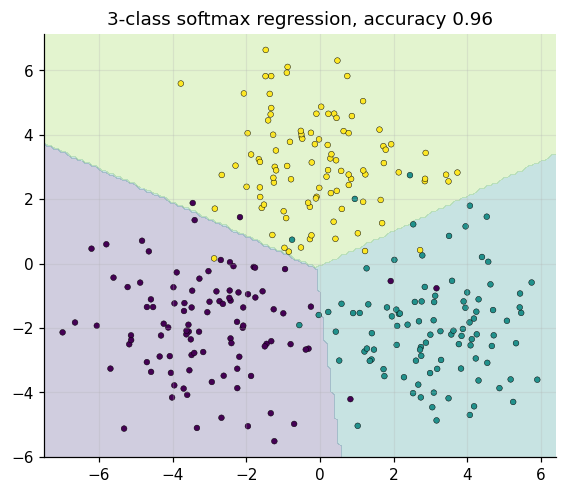

In [3]:
from sklearn.datasets import make_blobs
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

X, y = make_blobs(n_samples=300, centers=[[-3, -2], [3, -2], [0, 3.5]], cluster_std=1.5, random_state=2)
m = SoftmaxRegression(lr=0.1, n_iters=1000).fit(X, y)
fig, ax = plt.subplots(figsize=(6, 5))
plot_boundary(ax, m, X, y, cmap="viridis"); ax.set_title(f"3-class softmax regression, accuracy {(m.predict(X) == y).mean():.2f}"); plt.show()

### 2. Probabilities, not just labels

For a few points, the model's class probabilities. Points deep inside a region get near-1 for one class; points near a border split their probability.

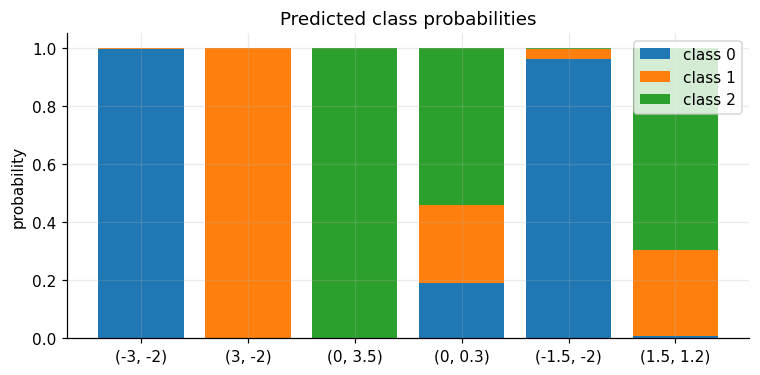

In [4]:
pts = np.array([[-3, -2], [3, -2], [0, 3.5], [0, 0.3], [-1.5, -2], [1.5, 1.2]])
probs = m.predict_proba(pts)
fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(pts))
for k in range(3):
    ax.bar(range(len(pts)), probs[:, k], bottom=bottom, label=f"class {k}"); bottom += probs[:, k]
ax.set_xticks(range(len(pts))); ax.set_xticklabels([f"({a:g}, {b:g})" for a, b in pts]); ax.set_ylabel("probability"); ax.legend(); ax.set_title("Predicted class probabilities"); plt.show()

### 3. Training: the loss curve and the learning rate

`loss_history_` records the cross-entropy at each gradient step. A larger learning rate gets there faster (until it becomes unstable).

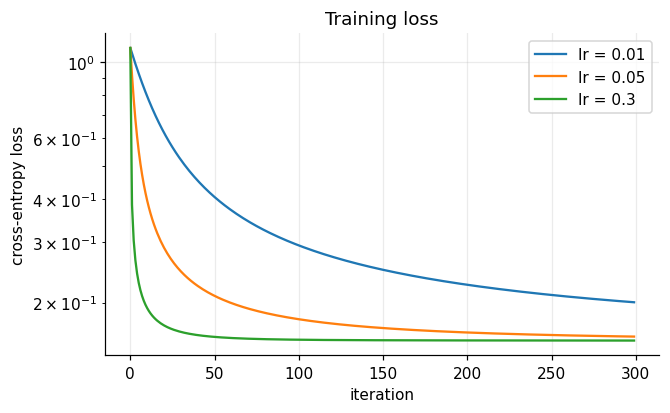

In [5]:
plt.figure(figsize=(6.5, 3.8))
for lr in (0.01, 0.05, 0.3):
    plt.plot(SoftmaxRegression(lr=lr, n_iters=300).fit(X, y).loss_history_, label=f"lr = {lr}")
plt.xlabel("iteration"); plt.ylabel("cross-entropy loss"); plt.yscale("log"); plt.legend(); plt.title("Training loss"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

ours = SoftmaxRegression(lr=0.1, n_iters=2000).fit(X_train, y_train)
theirs = LogisticRegression(penalty=None, max_iter=2000).fit(X_train, y_train)  # multinomial by default

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("iris (3 classes) test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
print("loss: %.4f -> %.4f" % (ours.loss_history_[0], ours.loss_history_[-1]))
assert abs(acc_ours - acc_theirs) < 0.03

iris (3 classes) test accuracy: ours=1.0000 sklearn=1.0000
loss: 1.0986 -> 0.0997


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_softmax_rows_sum_to_one_and_survive_huge_logits():
    P = _softmax(np.array([[1000.0, 1001.0, 999.0], [0.0, 0.0, 0.0]]))
    assert np.allclose(P.sum(axis=1), 1.0)
    assert np.isfinite(P).all()
    assert np.allclose(P[1], 1 / 3)


def test_three_blobs_with_string_labels():
    rng = np.random.default_rng(0)
    centers = np.array([[-4, 0], [4, 0], [0, 5]])
    X = np.vstack([rng.normal(c, 0.7, (50, 2)) for c in centers])
    y = np.repeat(np.array(["red", "green", "blue"]), 50)

    model = SoftmaxRegression(lr=0.2, n_iters=500).fit(X, y)
    assert (model.predict(X) == y).mean() > 0.98
    assert np.allclose(model.predict_proba(X).sum(axis=1), 1.0)
    assert model.loss_history_[-1] < model.loss_history_[0]


def test_two_classes_reduces_to_logistic_regression():
    rng = np.random.default_rng(1)
    X = np.vstack([rng.normal(-2, 1, (80, 2)), rng.normal(2, 1, (80, 2))])
    y = np.array([0] * 80 + [1] * 80)
    assert (SoftmaxRegression(n_iters=500).fit(X, y).predict(X) == y).mean() > 0.95

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_softmax_rows_sum_to_one_and_survive_huge_logits
PASS test_three_blobs_with_string_labels
PASS test_two_classes_reduces_to_logistic_regression

all 3 tests passed


## Takeaways

- **Use it** as the natural multiclass extension of logistic regression, and as the **output layer of every classification neural net** (`26_neural_network`). With 2 classes it is equivalent to logistic regression.
- **Loss and gradient:** cross-entropy `−mean(log p_true)`, gradient `Xᵀ(P − Y)/n` with `Y` one-hot; always subtract the row max before `exp` (stable softmax).
- **Limits:** linear boundaries only; scale the features.
- **Interview line:** *"One linear score per class, softmax, cross-entropy; the gradient is `Xᵀ(P − Y)/n`."*